In [9]:
# Install the required packages
!pip install pandas numpy scikit-learn imbalanced-learn torch matplotlib seaborn joblib


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
# from sklearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


In [4]:
# Load data
DATA_PATH = "data/creditcard.csv"

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print(df.head())

Shape: (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26 

In [5]:
# data validations:
required = (
    ["Time"]
    + [f"V{i}" for i in range(1, 29)]
    + ["Amount", "Class"]
)

missing = [
    col for col in required
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing columns: {missing}"
    )

df["Class"] = pd.to_numeric(
    df["Class"],
    errors="coerce"
)

invalid_classes = set(
    df["Class"].dropna().unique()
) - {0, 1}

if invalid_classes:
    raise ValueError(
        f"Unexpected Class values: {invalid_classes}"
    )

print("Dataset is valid.")

print("\nShape:", df.shape)

print("\nMissing values:")
print(df[required].isnull().sum().sum())

print("\nClass distribution:")
print(df["Class"].value_counts())

print("\nClass percentage:")
print(
    df["Class"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print(
    f"\nFraud percentage: "
    f"{df['Class'].mean() * 100:.3f}%"
)

Dataset is valid.

Shape: (284807, 31)

Missing values:
0

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Fraud percentage: 0.173%


In [6]:
df = df.sort_values(
    "Time"
).reset_index(drop=True)

print(df[["Time", "Class"]].head(10))

   Time  Class
0   0.0      0
1   0.0      0
2   1.0      0
3   1.0      0
4   2.0      0
5   2.0      0
6   4.0      0
7   7.0      0
8   7.0      0
9   9.0      0


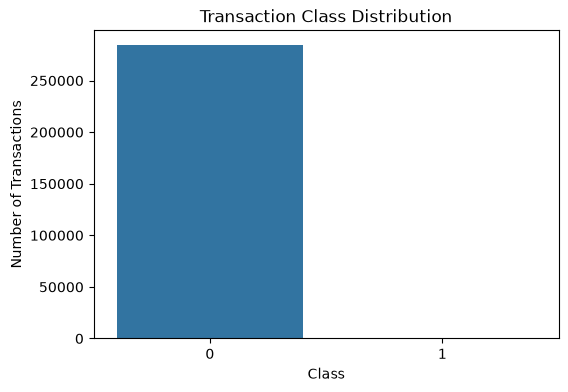

In [7]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Class"
)

plt.title("Transaction Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Transactions")

plt.show()

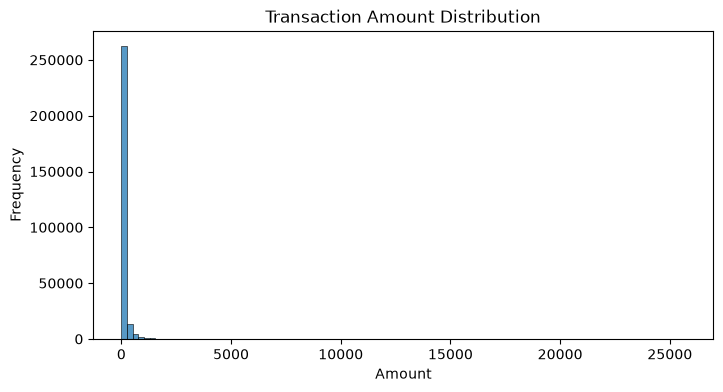

In [8]:
plt.figure(figsize=(8, 4))

sns.histplot(
    df["Amount"],
    bins=100
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Amount")
plt.ylabel("Frequency")

plt.show()

In [9]:
print(
    df.groupby("Class")["Amount"]
    .describe()
)

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


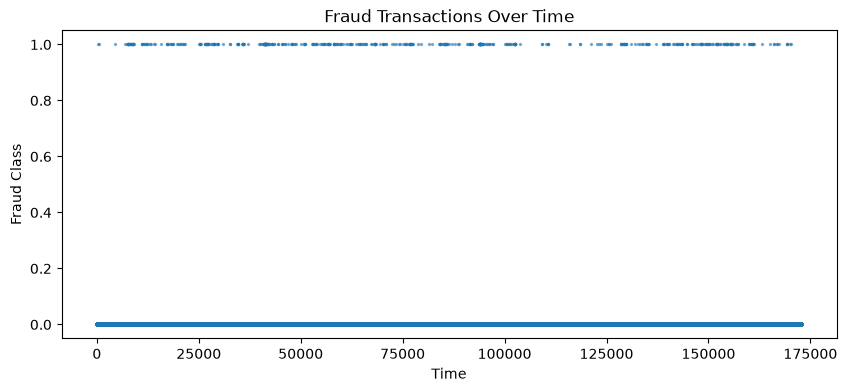

In [10]:
# time based analysis

plt.figure(figsize=(10, 4))

plt.scatter(
    df["Time"],
    df["Class"],
    s=2,
    alpha=0.5
)

plt.xlabel("Time")
plt.ylabel("Fraud Class")
plt.title("Fraud Transactions Over Time")

plt.show()

In [11]:
df["TimeHour"] = (
    df["Time"] / 3600
)

df["TimeHourOfDay"] = (
    (df["Time"] % 86400) / 3600
)

In [12]:
# feature defination
df["TimeHour"] = df["Time"] / 3600

df["TimeOfDay"] = (
    (df["Time"] % 86400) / 3600
)

df["TimeSincePrevious"] = (
    df["Time"]
    .diff()
    .fillna(0)
)

In [13]:
FEATURES = (
    ["Time"]
    + [f"V{i}" for i in range(1, 29)]
    + [
        "Amount",
        "TimeHour",
        "TimeOfDay",
        "TimeSincePrevious"
    ]
)

TARGET = "Class"

X = df[FEATURES].values
y = df[TARGET].values

print("Number of features:", len(FEATURES))

Number of features: 33


In [14]:
#  Chronological train/validation/test split

n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain fraud rate:")
print(train_df["Class"].mean())

print("\nValidation fraud rate:")
print(val_df["Class"].mean())

print("\nTest fraud rate:")
print(test_df["Class"].mean())

Train: (199364, 35)
Validation: (42721, 35)
Test: (42722, 35)

Train fraud rate:
0.0019261250777472363

Validation fraud rate:
0.001310830738980829

Test fraud rate:
0.0012171714807359207


In [15]:
#Scale the features

scaler = StandardScaler()

X_train = scaler.fit_transform(
    train_df[FEATURES]
)

X_val = scaler.transform(
    val_df[FEATURES]
)

X_test = scaler.transform(
    test_df[FEATURES]
)

y_train = train_df[TARGET].values
y_val = val_df[TARGET].values
y_test = test_df[TARGET].values

In [16]:
SEQUENCE_LENGTH = 20

In [17]:
def create_sequences(X, y, sequence_length):
    sequences = []
    labels = []

    for i in range(
        sequence_length,
        len(X)
    ):
        sequences.append(
            X[
                i-sequence_length:i
            ]
        )

        labels.append(
            y[i]
        )

    return (
        np.array(sequences),
        np.array(labels)
    )

In [18]:
#create sequence
X_train_seq, y_train_seq = create_sequences(
    X_train,
    y_train,
    SEQUENCE_LENGTH
)

X_val_seq, y_val_seq = create_sequences(
    X_val,
    y_val,
    SEQUENCE_LENGTH
)

X_test_seq, y_test_seq = create_sequences(
    X_test,
    y_test,
    SEQUENCE_LENGTH
)

print("Train sequences:", X_train_seq.shape)
print("Validation sequences:", X_val_seq.shape)
print("Test sequences:", X_test_seq.shape)

Train sequences: (199344, 20, 33)
Validation sequences: (42701, 20, 33)
Test sequences: (42702, 20, 33)


In [19]:
class FraudDataset(Dataset):

    def __init__(self, X, y):
        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return (
            self.X[idx],
            self.y[idx]
        )

In [20]:
train_dataset = FraudDataset(
    X_train_seq,
    y_train_seq
)

val_dataset = FraudDataset(
    X_val_seq,
    y_val_seq
)

test_dataset = FraudDataset(
    X_test_seq,
    y_test_seq
)

In [21]:
# data loader

BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [22]:
# LSTM model

class FraudLSTM(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=128,
        embedding_size=64,
        num_layers=2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )

        self.embedding = nn.Linear(
            hidden_size,
            embedding_size
        )

        self.output = nn.Linear(
            embedding_size,
            1
        )

    def forward(self, x):

        output, _ = self.lstm(x)

        last_output = output[:, -1, :]

        embedding = self.embedding(
            last_output
        )

        embedding = torch.relu(
            embedding
        )

        logits = self.output(
            embedding
        )

        return logits, embedding

In [23]:
#initialize
model = FraudLSTM(
    input_size=len(FEATURES),
    hidden_size=128,
    embedding_size=64,
    num_layers=2
).to(DEVICE)

print(model)

FraudLSTM(
  (lstm): LSTM(33, 128, num_layers=2, batch_first=True, dropout=0.2)
  (embedding): Linear(in_features=128, out_features=64, bias=True)
  (output): Linear(in_features=64, out_features=1, bias=True)
)


In [24]:
# hadnle class imbalance
negative = np.sum(
    y_train_seq == 0
)

positive = np.sum(
    y_train_seq == 1
)

pos_weight = torch.tensor(
    [negative / positive],
    dtype=torch.float32
).to(DEVICE)

print("Negative:", negative)
print("Positive:", positive)
print("Positive weight:", pos_weight.item())

Negative: 198960
Positive: 384
Positive weight: 518.125


In [25]:
criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
# train LSTM
EPOCHS = 10

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    model.train()

    train_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        optimizer.zero_grad()

        logits, _ = model(
            X_batch
        )

        loss = criterion(
            logits.squeeze(),
            y_batch
        )

        loss.backward()

        optimizer.step()

        train_loss += (
            loss.item()
        )

    train_loss /= len(train_loader)

    model.eval()

    val_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            logits, _ = model(
                X_batch
            )

            loss = criterion(
                logits.squeeze(),
                y_batch
            )

            val_loss += loss.item()

    val_loss /= len(val_loader)

    print(
        f"Epoch {epoch+1}/{EPOCHS} "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_fraud_lstm.pt"
        )

Epoch 1/10 | Train Loss: 1.3737 | Val Loss: 1.1363
Epoch 2/10 | Train Loss: 1.2787 | Val Loss: 1.1223
Epoch 3/10 | Train Loss: 1.2510 | Val Loss: 1.1174
Epoch 4/10 | Train Loss: 1.2389 | Val Loss: 1.1291
Epoch 5/10 | Train Loss: 1.1966 | Val Loss: 1.1578
Epoch 6/10 | Train Loss: 1.1535 | Val Loss: 1.2185
Epoch 7/10 | Train Loss: 1.0851 | Val Loss: 1.2682
Epoch 8/10 | Train Loss: 0.9344 | Val Loss: 1.5556
Epoch 9/10 | Train Loss: 0.8495 | Val Loss: 1.8781


In [ ]:
#extract lstm embeddings
model.load_state_dict(
    torch.load(
        "best_fraud_lstm.pt",
        map_location=DEVICE
    )
)

model.eval()

In [ ]:
def extract_embeddings(
    model,
    loader
):

    embeddings = []
    labels = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(DEVICE)

            _, embedding = model(
                X_batch
            )

            embeddings.append(
                embedding.cpu().numpy()
            )

            labels.append(
                y_batch.numpy()
            )

    return (
        np.vstack(embeddings),
        np.concatenate(labels)
    )

In [ ]:
train_embeddings, train_labels = extract_embeddings(
    model,
    train_loader
)

val_embeddings, val_labels = extract_embeddings(
    model,
    val_loader
)

test_embeddings, test_labels = extract_embeddings(
    model,
    test_loader
)

print(
    "Embedding shape:",
    train_embeddings.shape
)

In [ ]:
#align tabular features
X_train_tab = X_train[
    SEQUENCE_LENGTH:
]

X_val_tab = X_val[
    SEQUENCE_LENGTH:
]

X_test_tab = X_test[
    SEQUENCE_LENGTH:
]

In [ ]:
print(
    X_train_tab.shape,
    train_embeddings.shape
)

print(
    X_val_tab.shape,
    val_embeddings.shape
)

print(
    X_test_tab.shape,
    test_embeddings.shape
)

In [ ]:
#hybrid feature fusion
X_train_hybrid = np.hstack([
    X_train_tab,
    train_embeddings
])

X_val_hybrid = np.hstack([
    X_val_tab,
    val_embeddings
])

X_test_hybrid = np.hstack([
    X_test_tab,
    test_embeddings
])

print(
    "Hybrid feature shape:",
    X_train_hybrid.shape
)

In [ ]:
#balanced random forest
hybrid_model = BalancedRandomForestClassifier(
    n_estimators=300,
    random_state=SEED,
    n_jobs=-1,
    sampling_strategy="all",
    replacement=True
)

hybrid_model.fit(
    X_train_hybrid,
    train_labels
)